<a href="https://colab.research.google.com/github/Aishwariyabennuri/Deep_Learning_CaseStudy/blob/main/Deep_LearningCS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TensorFlow version: 2.21.0

Using Colab cache for faster access to the 'fashion-product-images-dataset' dataset.
Dataset path: /kaggle/input/fashion-product-images-dataset
CSV found: /kaggle/input/fashion-product-images-dataset/fashion-dataset/styles.csv

Original dataset shape: (44424, 10)

Finding product images...

Usable dataset: (44419, 11)

Gender distribution:
gender
Men       22142
Women     18631
Unisex     2161
Boys        830
Girls       655
Name: count, dtype: int64

Article types:
articleType
Tshirts                  7066
Shirts                   3215
Casual Shoes             2845
Watches                  2542
Sports Shoes             2036
Kurtas                   1844
Tops                     1762
Handbags                 1759
Heels                    1323
Sunglasses               1073
Wallets                   936
Flip Flops                914
Sandals                   897
Briefs                    849
Belts                     813
Backpacks                 724
Socks    

Extracting features:   0%|          | 0/44419 [00:00<?, ?it/s]


Feature matrix shape: (44419, 2048)
Final catalog size: 44419

Gender classes:
['Boys', 'Girls', 'Men', 'Unisex', 'Women']

Article classes:
['Accessory Gift Set', 'Baby Dolls', 'Backpacks', 'Bangle', 'Basketballs', 'Bath Robe', 'Beauty Accessory', 'Belts', 'Blazers', 'Body Lotion', 'Body Wash and Scrub', 'Booties', 'Boxers', 'Bra', 'Bracelet', 'Briefs', 'Camisoles', 'Capris', 'Caps', 'Casual Shoes', 'Churidar', 'Clothing Set', 'Clutches', 'Compact', 'Concealer', 'Cufflinks', 'Cushion Covers', 'Deodorant', 'Dresses', 'Duffel Bag', 'Dupatta', 'Earrings', 'Eye Cream', 'Eyeshadow', 'Face Moisturisers', 'Face Scrub and Exfoliator', 'Face Serum and Gel', 'Face Wash and Cleanser', 'Flats', 'Flip Flops', 'Footballs', 'Formal Shoes', 'Foundation and Primer', 'Fragrance Gift Set', 'Free Gifts', 'Gloves', 'Hair Accessory', 'Hair Colour', 'Handbags', 'Hat', 'Headband', 'Heels', 'Highlighter and Blush', 'Innerwear Vests', 'Ipad', 'Jackets', 'Jeans', 'Jeggings', 'Jewellery Set', 'Jumpsuit', 'Kajal

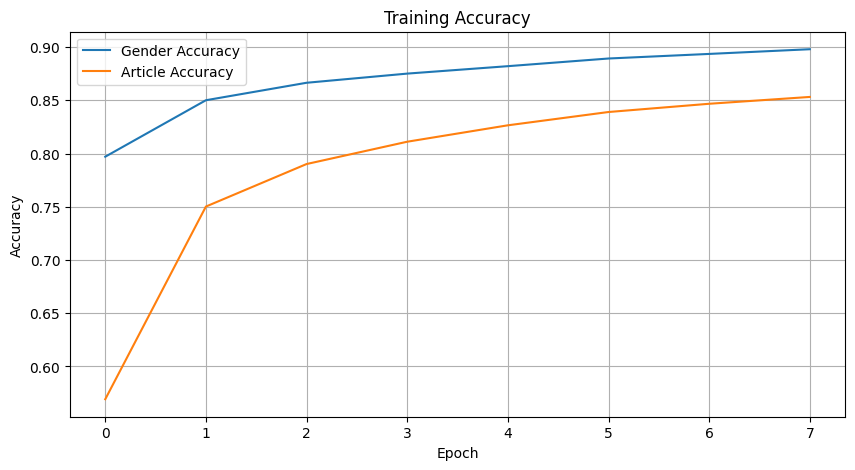


UPLOAD YOUR FASHION IMAGE


Saving mine1.jpg to mine1.jpg

Input image: mine1.jpg


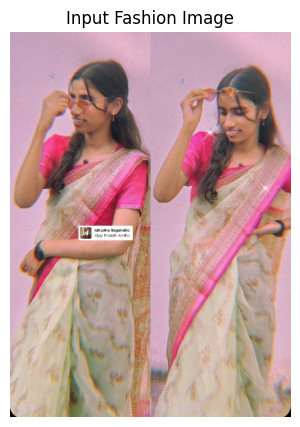


QUERY PREDICTION
Predicted Gender       : Women
Gender Confidence      : 99.88%
Predicted Article Type : Sarees
Article Confidence     : 71.75%

Matching catalog products: 427

TOP SIMILAR PRODUCTS


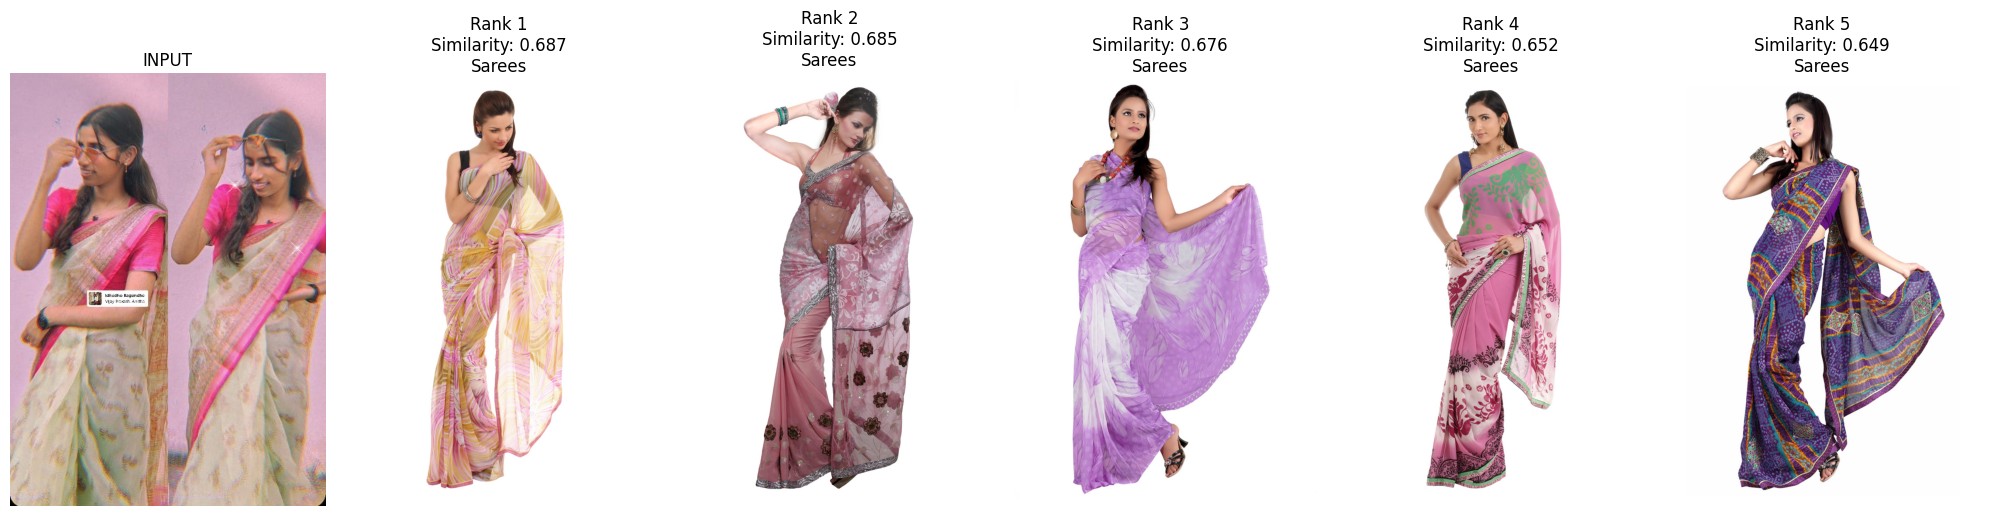


RESULT DETAILS

Rank 1
Product: FNF Pink & Yellow Printed Evening Wear Sari
Gender: Women
Article Type: Sarees
Colour: Yellow
Similarity Score: 0.6865

Rank 2
Product: FNF Pink Collection for Wedding Wear Sari
Gender: Women
Article Type: Sarees
Colour: Pink
Similarity Score: 0.6850

Rank 3
Product: FNF Purple Sari
Gender: Women
Article Type: Sarees
Colour: Purple
Similarity Score: 0.6757

Rank 4
Product: FNF Multi Coloured Printed Sari
Gender: Women
Article Type: Sarees
Colour: Multi
Similarity Score: 0.6519

Rank 5
Product: FNF Purple Printed Sari
Gender: Women
Article Type: Sarees
Colour: Purple
Similarity Score: 0.6493

VISUAL SEARCH COMPLETED


In [ ]:
# ============================================================
# DEEP LEARNING BASED FASHION VISUAL SEARCH SYSTEM
# ResNet50 + Feature Extraction + Metadata Filtering
# ============================================================

!pip install -q kagglehub tensorflow scikit-learn pandas matplotlib pillow tqdm

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import tensorflow as tf
import kagglehub

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from google.colab import files

print("TensorFlow version:", tf.__version__)

# ============================================================
# 1. DOWNLOAD DATASET
# ============================================================

print("\nDownloading Fashion Product Images Dataset...")

dataset_path = kagglehub.dataset_download(
    "paramaggarwal/fashion-product-images-dataset"
)

print("Dataset path:", dataset_path)

# ============================================================
# 2. FIND styles.csv
# ============================================================

styles_csv = None

for root, dirs, files_list in os.walk(dataset_path):
    for file in files_list:
        if file.lower() == "styles.csv":
            styles_csv = os.path.join(root, file)
            break
    if styles_csv:
        break

if styles_csv is None:
    raise FileNotFoundError("styles.csv not found!")

print("CSV found:", styles_csv)

# ============================================================
# 3. LOAD CSV
# ============================================================

df = pd.read_csv(
    styles_csv,
    engine="python",
    on_bad_lines="skip"
)

print("\nOriginal dataset shape:", df.shape)

# ============================================================
# 4. FIND IMAGE FILES
# ============================================================

print("\nFinding product images...")

image_dict = {}

for root, dirs, files_list in os.walk(dataset_path):

    for file in files_list:

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_id = os.path.splitext(file)[0]

            if image_id not in image_dict:
                image_dict[image_id] = os.path.join(root, file)

df["image_path"] = df["id"].astype(str).map(image_dict)

# Keep only products having images
df = df.dropna(subset=["image_path"]).copy()

# ============================================================
# 5. CLEAN METADATA
# ============================================================

required_columns = [
    "gender",
    "articleType",
    "baseColour"
]

for col in required_columns:

    if col not in df.columns:
        df[col] = "Unknown"

    df[col] = df[col].fillna("Unknown").astype(str)

df = df[
    (df["gender"] != "Unknown") &
    (df["articleType"] != "Unknown")
].copy()

print("\nUsable dataset:", df.shape)

print("\nGender distribution:")
print(df["gender"].value_counts().head(10))

print("\nArticle types:")
print(df["articleType"].value_counts().head(20))

# ============================================================
# 6. LOAD PRE-TRAINED RESNET50
# ============================================================

print("\nLoading ResNet50...")

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

feature_model = Model(
    inputs=base_model.input,
    outputs=GlobalAveragePooling2D()(base_model.output)
)

print("ResNet50 loaded successfully.")

# ============================================================
# 7. IMAGE FEATURE EXTRACTION FUNCTION
# ============================================================

def extract_features(image_paths, batch_size=64):

    features = []
    valid_paths = []

    batch_images = []
    batch_paths = []

    for path in tqdm(image_paths, desc="Extracting features"):

        try:

            img = Image.open(path).convert("RGB")
            img = img.resize((224, 224))

            arr = np.array(img, dtype=np.float32)

            batch_images.append(arr)
            batch_paths.append(path)

            if len(batch_images) == batch_size:

                batch = np.array(batch_images)

                batch = preprocess_input(batch)

                batch_features = feature_model.predict(
                    batch,
                    verbose=0
                )

                features.append(batch_features)
                valid_paths.extend(batch_paths)

                batch_images = []
                batch_paths = []

        except Exception:
            continue

    # Remaining images
    if len(batch_images) > 0:

        batch = np.array(batch_images)

        batch = preprocess_input(batch)

        batch_features = feature_model.predict(
            batch,
            verbose=0
        )

        features.append(batch_features)
        valid_paths.extend(batch_paths)

    if len(features) == 0:
        raise ValueError("No images could be processed.")

    features = np.vstack(features)

    # Normalize feature vectors
    norms = np.linalg.norm(
        features,
        axis=1,
        keepdims=True
    )

    features = features / (norms + 1e-10)

    return features, valid_paths


# ============================================================
# 8. EXTRACT CATALOG FEATURES
# ============================================================

print("\nExtracting catalog features...")

catalog_features, valid_paths = extract_features(
    df["image_path"].tolist(),
    batch_size=64
)

# Keep dataframe aligned with successfully processed images
path_to_index = {
    path: i for i, path in enumerate(valid_paths)
}

df = df[
    df["image_path"].isin(path_to_index)
].copy()

df = df.set_index("image_path").loc[valid_paths].reset_index()

print("\nFeature matrix shape:", catalog_features.shape)
print("Final catalog size:", len(df))

# ============================================================
# 9. LABEL ENCODING
# ============================================================

gender_encoder = LabelEncoder()
article_encoder = LabelEncoder()

y_gender = gender_encoder.fit_transform(
    df["gender"]
)

y_article = article_encoder.fit_transform(
    df["articleType"]
)

print("\nGender classes:")
print(list(gender_encoder.classes_))

print("\nArticle classes:")
print(list(article_encoder.classes_))

# ============================================================
# 10. TRAIN / VALIDATION SPLIT
# ============================================================

X = catalog_features

try:

    X_train, X_val, \
    y_gender_train, y_gender_val, \
    y_article_train, y_article_val = train_test_split(
        X,
        y_gender,
        y_article,
        test_size=0.20,
        random_state=42,
        stratify=y_gender
    )

except:

    X_train, X_val, \
    y_gender_train, y_gender_val, \
    y_article_train, y_article_val = train_test_split(
        X,
        y_gender,
        y_article,
        test_size=0.20,
        random_state=42
    )

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))

# ============================================================
# 11. CLASSIFICATION HEAD
# ============================================================

feature_dim = X.shape[1]

input_features = tf.keras.Input(
    shape=(feature_dim,),
    name="feature_input"
)

x = Dense(
    512,
    activation="relu"
)(input_features)

x = Dropout(0.4)(x)

gender_output = Dense(
    len(gender_encoder.classes_),
    activation="softmax",
    name="gender"
)(x)

article_output = Dense(
    len(article_encoder.classes_),
    activation="softmax",
    name="article"
)(x)

classifier = Model(
    inputs=input_features,
    outputs=[
        gender_output,
        article_output
    ]
)

# ============================================================
# 12. COMPILE MODEL
# ============================================================

classifier.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss={
        "gender": "sparse_categorical_crossentropy",
        "article": "sparse_categorical_crossentropy"
    },

    # IMPORTANT:
    # There are TWO outputs, so metrics are specified
    # separately for both outputs.
    metrics={
        "gender": "accuracy",
        "article": "accuracy"
    }
)

print("\nClassifier compiled successfully.")

# ============================================================
# 13. TRAIN CLASSIFIER
# ============================================================

print("\nTraining classification head...")

history = classifier.fit(

    X_train,

    {
        "gender": y_gender_train,
        "article": y_article_train
    },

    validation_data=(

        X_val,

        {
            "gender": y_gender_val,
            "article": y_article_val
        }

    ),

    epochs=8,

    batch_size=128,

    verbose=1
)

print("\nTraining completed.")

# ============================================================
# 14. PLOT TRAINING ACCURACY
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["gender_accuracy"],
    label="Gender Accuracy"
)

plt.plot(
    history.history["article_accuracy"],
    label="Article Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.legend()
plt.grid(True)

plt.show()

# ============================================================
# 15. UPLOAD QUERY IMAGE
# ============================================================

print("\n============================================")
print("UPLOAD YOUR FASHION IMAGE")
print("============================================")

uploaded = files.upload()

query_file = list(uploaded.keys())[0]

print("\nInput image:", query_file)

# ============================================================
# 16. DISPLAY INPUT IMAGE
# ============================================================

query_img = Image.open(query_file).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(query_img)
plt.axis("off")
plt.title("Input Fashion Image")
plt.show()

# ============================================================
# 17. EXTRACT QUERY FEATURE
# ============================================================

img = query_img.resize((224, 224))

query_array = np.array(
    img,
    dtype=np.float32
)

query_array = np.expand_dims(
    query_array,
    axis=0
)

query_array = preprocess_input(
    query_array
)

query_feature = feature_model.predict(
    query_array,
    verbose=0
)

query_feature = query_feature / (
    np.linalg.norm(
        query_feature,
        axis=1,
        keepdims=True
    ) + 1e-10
)

# ============================================================
# 18. PREDICT GENDER AND ARTICLE TYPE
# ============================================================

gender_prediction, article_prediction = classifier.predict(
    query_feature,
    verbose=0
)

predicted_gender_index = np.argmax(
    gender_prediction[0]
)

predicted_article_index = np.argmax(
    article_prediction[0]
)

predicted_gender = gender_encoder.inverse_transform(
    [predicted_gender_index]
)[0]

predicted_article = article_encoder.inverse_transform(
    [predicted_article_index]
)[0]

gender_confidence = (
    gender_prediction[0][predicted_gender_index] * 100
)

article_confidence = (
    article_prediction[0][predicted_article_index] * 100
)

print("\n============================================")
print("QUERY PREDICTION")
print("============================================")

print(
    f"Predicted Gender       : {predicted_gender}"
)

print(
    f"Gender Confidence      : {gender_confidence:.2f}%"
)

print(
    f"Predicted Article Type : {predicted_article}"
)

print(
    f"Article Confidence     : {article_confidence:.2f}%"
)

# ============================================================
# 19. STRICT METADATA FILTERING
# ============================================================

filtered_df = df[
    (df["gender"] == predicted_gender) &
    (df["articleType"] == predicted_article)
].copy()

filtered_indices = [
    path_to_index[p]
    for p in filtered_df["image_path"]
    if p in path_to_index
]

print("\nMatching catalog products:", len(filtered_indices))

# ============================================================
# 20. FALLBACK IF EXACT MATCHES ARE TOO FEW
# ============================================================

if len(filtered_indices) < 5:

    print(
        "\nNot enough exact category products."
    )

    print(
        "Using gender-only filtering..."
    )

    filtered_df = df[
        df["gender"] == predicted_gender
    ].copy()

    filtered_indices = [
        path_to_index[p]
        for p in filtered_df["image_path"]
        if p in path_to_index
    ]

# ============================================================
# 21. COSINE SIMILARITY
# ============================================================

candidate_features = catalog_features[
    filtered_indices
]

similarities = cosine_similarity(
    query_feature,
    candidate_features
)[0]

# Sort from highest similarity to lowest
sorted_indices = np.argsort(
    similarities
)[::-1]

top_k = min(
    5,
    len(sorted_indices)
)

top_indices = sorted_indices[:top_k]

# ============================================================
# 22. DISPLAY TOP 5 RESULTS
# ============================================================

print("\n============================================")
print("TOP SIMILAR PRODUCTS")
print("============================================")

fig, axes = plt.subplots(
    1,
    top_k + 1,
    figsize=(20, 5)
)

# Input image
axes[0].imshow(query_img)
axes[0].axis("off")
axes[0].set_title("INPUT")

for rank, result_position in enumerate(
    top_indices,
    start=1
):

    original_index = filtered_indices[
        result_position
    ]

    result_row = df.iloc[
        original_index
    ]

    result_path = result_row[
        "image_path"
    ]

    score = similarities[
        result_position
    ]

    result_img = Image.open(
        result_path
    ).convert("RGB")

    axes[rank].imshow(result_img)
    axes[rank].axis("off")

    axes[rank].set_title(
        f"Rank {rank}\n"
        f"Similarity: {score:.3f}\n"
        f"{result_row['articleType']}"
    )

plt.tight_layout()
plt.show()

# ============================================================
# 23. PRINT RESULT DETAILS
# ============================================================

print("\n============================================")
print("RESULT DETAILS")
print("============================================")

for rank, result_position in enumerate(
    top_indices,
    start=1
):

    original_index = filtered_indices[
        result_position
    ]

    result_row = df.iloc[
        original_index
    ]

    score = similarities[
        result_position
    ]

    print(
        f"\nRank {rank}"
    )

    print(
        "Product:",
        result_row.get(
            "productDisplayName",
            "N/A"
        )
    )

    print(
        "Gender:",
        result_row["gender"]
    )

    print(
        "Article Type:",
        result_row["articleType"]
    )

    print(
        "Colour:",
        result_row["baseColour"]
    )

    print(
        f"Similarity Score: {score:.4f}"
    )

print("\n============================================")
print("VISUAL SEARCH COMPLETED")
print("============================================")